In [2]:
import pandas as pd

rf_results = pd.read_csv(
    "../results/tables/random_forest_feature_reduction.csv"
)

dt_results = pd.read_csv(
    "../results/tables/decision_tree_feature_reduction.csv"
)

gb_results = pd.read_csv(
    "../results/tables/gradient_boosting_feature_reduction.csv"
)

combined_reduction_results = pd.read_csv(
    "../results/tables/combined_feature_reduction_results.csv"
)

print("Random Forest:", rf_results.shape)
print("Decision Tree:", dt_results.shape)
print("Gradient Boosting:", gb_results.shape)
print("Combined:", combined_reduction_results.shape)

Random Forest: (4, 7)
Decision Tree: (3, 6)
Gradient Boosting: (3, 6)
Combined: (10, 8)


## Baseline Model Comparison

The baseline experiments evaluated seven classification algorithms using the complete set of 30 input features.

The following results are used as the reference point for comparing the classification models before feature reduction.


In [2]:
baseline_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "KNN",
        "Decision Tree",
        "Random Forest",
        "SVM",
        "Naive Bayes",
        "Gradient Boosting"
    ],
    "Accuracy": [
        0.9285,
        0.9489,
        0.9711,
        0.9742,
        0.9516,
        0.6006,
        0.9530
    ],
    "Precision": [
        0.9234,
        0.9501,
        0.9702,
        0.9696,
        0.9418,
        0.9971,
        0.9533
    ],
    "Recall": [
        0.9504,
        0.9586,
        0.9781,
        0.9846,
        0.9732,
        0.2835,
        0.9626
    ],
    "F1_Score": [
        0.9367,
        0.9543,
        0.9741,
        0.9770,
        0.9573,
        0.4415,
        0.9580
    ],
    "ROC_AUC": [
        0.9808,
        0.9869,
        0.9805,
        0.9977,
        0.9893,
        0.9702,
        0.9921
    ]
})

baseline_results

,Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC
0,Logistic Regression,0.9285,0.9234,0.9504,0.9367,0.9808
1,KNN,0.9489,0.9501,0.9586,0.9543,0.9869
2,Decision Tree,0.9711,0.9702,0.9781,0.9741,0.9805
3,Random Forest,0.9742,0.9696,0.9846,0.9770,0.9977
4,SVM,0.9516,0.9418,0.9732,0.9573,0.9893
5,Naive Bayes,0.6006,0.9971,0.2835,0.4415,0.9702
6,Gradient Boosting,0.9530,0.9533,0.9626,0.9580,0.9921


In [3]:
baseline_results.to_csv(
    "../results/tables/baseline_model_results.csv",
    index=False
)

print("Baseline model results saved.")

Baseline model results saved.


## Baseline Model Performance Comparison

The baseline experiments evaluated seven classification algorithms using all 30 input features. The following visualization compares their F1-scores.

F1-score is used as the primary comparison metric in this visualization because it balances precision and recall.

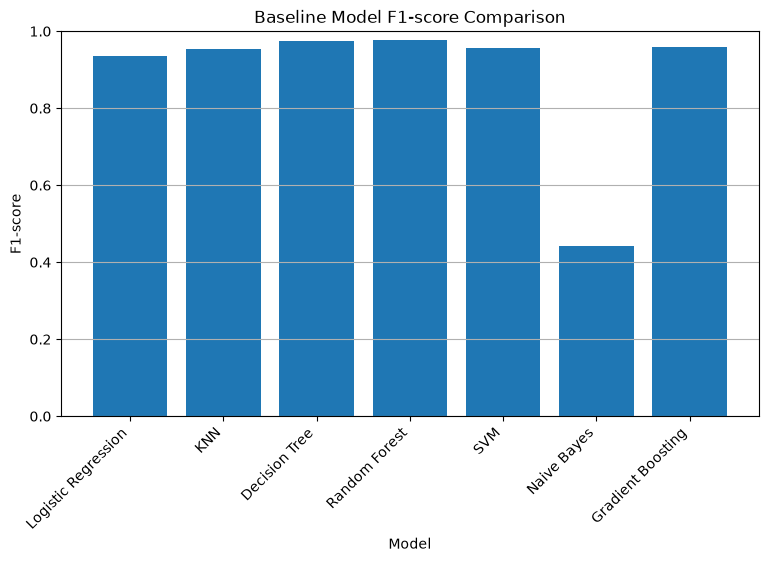

In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    baseline_results["Model"],
    baseline_results["F1_Score"]
)

plt.xlabel("Model")
plt.ylabel("F1-score")
plt.title("Baseline Model F1-score Comparison")
plt.xticks(rotation=45, ha="right")
plt.ylim(0, 1)
plt.grid(axis="y")

plt.show()

### Observation: Baseline Model Performance

The baseline comparison shows differences in classification performance among the seven machine learning models. Random Forest achieves the highest F1-score (0.9770), followed closely by Decision Tree (0.9741). Gradient Boosting, SVM, and KNN also achieve F1-scores above 0.95.

Logistic Regression achieves an F1-score of 0.9367, while Naive Bayes shows a substantially lower F1-score of 0.4415. The low F1-score of Naive Bayes is associated with its low recall (0.2835), despite its high precision (0.9971).

Overall, the baseline results show that the tree-based ensemble models perform strongly on this dataset, while model performance varies considerably across algorithms.

## Baseline ROC-AUC Comparison

ROC-AUC measures how well a classifier distinguishes between the two classes across different classification thresholds.

The following visualization compares the ROC-AUC values of the seven baseline models.

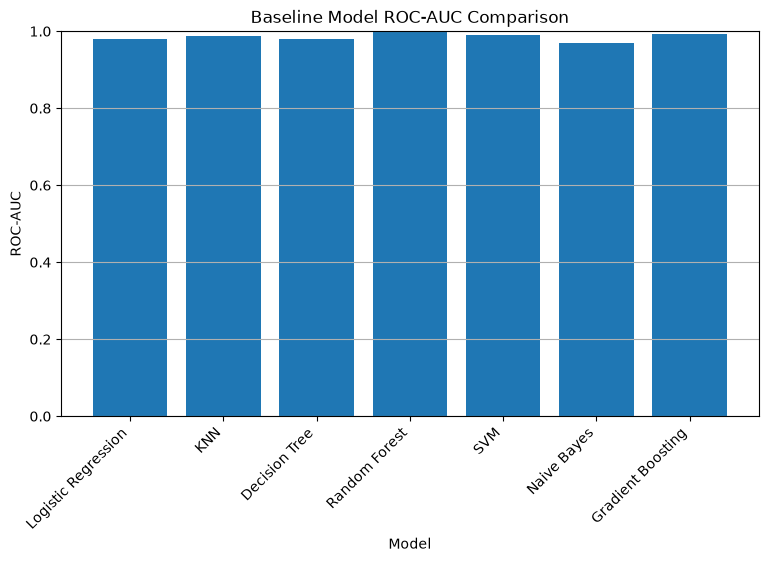

In [5]:
plt.figure(figsize=(9, 5))

plt.bar(
    baseline_results["Model"],
    baseline_results["ROC_AUC"]
)

plt.xlabel("Model")
plt.ylabel("ROC-AUC")
plt.title("Baseline Model ROC-AUC Comparison")
plt.xticks(rotation=45, ha="right")
plt.ylim(0, 1)
plt.grid(axis="y")

plt.show()

### Observation: Baseline ROC-AUC

The ROC-AUC comparison shows that all seven baseline models achieve relatively high ROC-AUC values, ranging from 0.9702 for Naive Bayes to 0.9977 for Random Forest.

Random Forest achieves the highest ROC-AUC, followed by Gradient Boosting and SVM. The relatively high ROC-AUC of Naive Bayes contrasts with its much lower F1-score.

This difference highlights that ROC-AUC and F1-score capture different aspects of classification performance. ROC-AUC evaluates the model's ability to distinguish between the two classes across different classification thresholds, whereas F1-score is calculated from precision and recall at the selected classification threshold.

Therefore, multiple evaluation metrics are considered when analyzing the models rather than relying on a single metric.

## Random Forest: Effect of Feature Reduction

Random Forest achieved strong baseline performance using all 30 features. The following comparison examines how its performance changes as the number of input features is reduced.

The 30-feature result represents the baseline, while the 20-, 15-, and 10-feature results represent progressively greater feature reduction.

In [6]:
rf_comparison = rf_results[
    [
        "Features",
        "Reduction_Percentage",
        "Accuracy",
        "Precision",
        "Recall",
        "F1_Score",
        "ROC_AUC"
    ]
].copy()

rf_comparison

,Features,Reduction_Percentage,Accuracy,Precision,Recall,F1_Score,ROC_AUC
0,30,0.0,0.974200,0.969600,0.984600,0.977000,0.997700
1,20,33.3,0.973768,0.970329,0.982941,0.976594,0.997500
2,15,50.0,0.970149,0.964884,0.982128,0.973430,0.996498
3,10,66.7,0.951606,0.946741,0.967506,0.957011,0.989297


In [7]:
rf_change = rf_comparison.copy()

baseline_row = rf_change[rf_change["Features"] == 30].iloc[0]

for metric in ["Accuracy", "Precision", "Recall", "F1_Score", "ROC_AUC"]:
    rf_change[f"{metric}_Change"] = (
        rf_change[metric] - baseline_row[metric]
    )

rf_change[
    [
        "Features",
        "Reduction_Percentage",
        "Accuracy_Change",
        "Precision_Change",
        "Recall_Change",
        "F1_Score_Change",
        "ROC_AUC_Change"
    ]
]

,Features,Reduction_Percentage,Accuracy_Change,Precision_Change,Recall_Change,F1_Score_Change,ROC_AUC_Change
0,30,0.0,0.000000,0.000000,0.000000,0.000000,0.000000
1,20,33.3,-0.000432,0.000729,-0.001659,-0.000406,-0.000200
2,15,50.0,-0.004051,-0.004716,-0.002472,-0.003570,-0.001202
3,10,66.7,-0.022594,-0.022859,-0.017094,-0.019989,-0.008403


### Observation: Quantitative Effect of Feature Reduction

The performance changes were calculated relative to the complete 30-feature Random Forest model.

Reducing the feature set by 33.3%, from 30 to 20 features, resulted in only a very small decrease in performance. The F1-score decreased by 0.000406, while accuracy decreased by 0.000432.

With a 50% reduction to 15 features, the decrease became more noticeable, with F1-score and accuracy decreasing by 0.003570 and 0.004051, respectively.

The largest change occurred after reducing the feature set by 66.7% to 10 features. The F1-score decreased by 0.019989 and accuracy decreased by 0.022594 compared with the 30-feature baseline.

These results indicate that moderate feature reduction can preserve most of the predictive performance of Random Forest, whereas aggressive feature reduction results in a more noticeable loss of performance.

## Cross-Model Effect of Feature Reduction

The feature-reduction results are compared across Random Forest, Decision Tree, and Gradient Boosting to examine whether reducing the number of input features affects different classifiers in a similar way.

F1-score is used for this comparison because it balances precision and recall.

In [8]:
f1_comparison = combined_reduction_results[
    ["Model", "Features", "F1_Score"]
].copy()

f1_comparison = f1_comparison.sort_values(
    ["Features", "Model"]
)

f1_comparison

,Model,Features,F1_Score
6,Decision Tree,10,0.954802
9,Gradient Boosting,10,0.949536
3,Random Forest,10,0.957011
5,Decision Tree,15,0.969231
8,Gradient Boosting,15,0.958417
2,Random Forest,15,0.973430
4,Decision Tree,20,0.973737
7,Gradient Boosting,20,0.957644
1,Random Forest,20,0.976594
0,Random Forest,30,0.977000


In [9]:
f1_full = pd.DataFrame({
    "Model": [
        "Random Forest",
        "Random Forest",
        "Random Forest",
        "Random Forest",
        "Decision Tree",
        "Decision Tree",
        "Decision Tree",
        "Gradient Boosting",
        "Gradient Boosting",
        "Gradient Boosting"
    ],
    "Features": [
        30, 20, 15, 10,
        30, 20, 15,
        30, 20, 15
    ],
    "F1_Score": [
        0.9770,
        0.976594,
        0.973430,
        0.957011,
        0.9741,
        0.973737,
        0.969231,
        0.9580,
        0.957644,
        0.958417
    ]
})

f1_full = f1_full.sort_values(
    ["Model", "Features"],
    ascending=[True, False]
).reset_index(drop=True)

f1_full

,Model,Features,F1_Score
0,Decision Tree,30,0.974100
1,Decision Tree,20,0.973737
2,Decision Tree,15,0.969231
3,Gradient Boosting,30,0.958000
4,Gradient Boosting,20,0.957644
5,Gradient Boosting,15,0.958417
6,Random Forest,30,0.977000
7,Random Forest,20,0.976594
8,Random Forest,15,0.973430
9,Random Forest,10,0.957011


In [10]:
f1_change = f1_full.copy()

baseline_f1 = (
    f1_full[f1_full["Features"] == 30]
    .set_index("Model")["F1_Score"]
)

f1_change["Baseline_F1"] = f1_change["Model"].map(baseline_f1)

f1_change["F1_Change"] = (
    f1_change["F1_Score"] - f1_change["Baseline_F1"]
)

f1_change

,Model,Features,F1_Score,Baseline_F1,F1_Change
0,Decision Tree,30,0.974100,0.9741,0.000000
1,Decision Tree,20,0.973737,0.9741,-0.000363
2,Decision Tree,15,0.969231,0.9741,-0.004869
3,Gradient Boosting,30,0.958000,0.9580,0.000000
4,Gradient Boosting,20,0.957644,0.9580,-0.000356
5,Gradient Boosting,15,0.958417,0.9580,0.000417
6,Random Forest,30,0.977000,0.9770,0.000000
7,Random Forest,20,0.976594,0.9770,-0.000406
8,Random Forest,15,0.973430,0.9770,-0.003570
9,Random Forest,10,0.957011,0.9770,-0.019989


### Observation: Cross-Model Effect of Feature Reduction

The effect of feature reduction was examined across Random Forest, Decision Tree, and Gradient Boosting using F1-score.

When the feature set was reduced from 30 to 20 features, all three models showed only very small changes in F1-score. The change was -0.000406 for Random Forest, -0.000363 for Decision Tree, and -0.000356 for Gradient Boosting.

At 15 features, the effect became more variable. Random Forest and Decision Tree showed decreases of 0.003570 and 0.004869 in F1-score, respectively, while Gradient Boosting showed a small increase of 0.000417 compared with its 30-feature baseline.

Overall, the experiments indicate that moderate feature reduction to 20 features preserved most of the F1 performance across the three evaluated classifiers. The effect of more substantial reduction varied by model, with larger performance changes observed for some classifiers.

In [3]:
top_10_features = pd.read_csv(
    "../results/tables/top_10_feature_importance.csv"
)

top_10_features

,Feature,Importance
0,SSLfinal_State,0.319667
1,URL_of_Anchor,0.250049
2,web_traffic,0.070803
3,having_Sub_Domain,0.069482
4,Links_in_tags,0.043887
5,Prefix_Suffix,0.037888
6,SFH,0.020226
7,Links_pointing_to_page,0.019292
8,Request_URL,0.017682
9,Domain_registeration_length,0.016681


In [4]:
final_model_summary = pd.DataFrame({
    "Model": [
        "Random Forest",
        "Decision Tree",
        "Gradient Boosting"
    ],
    "Features": [30, 30, 30],
    "Accuracy": [0.9742, 0.9711, 0.9530],
    "Precision": [0.9696, 0.9702, 0.9533],
    "Recall": [0.9846, 0.9781, 0.9626],
    "F1_Score": [0.9770, 0.9741, 0.9580],
    "ROC_AUC": [0.9977, 0.9805, 0.9921]
})

final_model_summary

,Model,Features,Accuracy,Precision,Recall,F1_Score,ROC_AUC
0,Random Forest,30,0.9742,0.9696,0.9846,0.9770,0.9977
1,Decision Tree,30,0.9711,0.9702,0.9781,0.9741,0.9805
2,Gradient Boosting,30,0.9530,0.9533,0.9626,0.9580,0.9921


In [5]:
final_model_summary.to_csv(
    "../results/tables/final_model_summary.csv",
    index=False
)

print("Final model summary saved.")

Final model summary saved.


In [6]:
reduced_20_summary = combined_reduction_results[
    combined_reduction_results["Features"] == 20
][
    [
        "Model",
        "Features",
        "Reduction_Percentage",
        "Accuracy",
        "Precision",
        "Recall",
        "F1_Score",
        "ROC_AUC"
    ]
].copy()

reduced_20_summary

,Model,Features,Reduction_Percentage,Accuracy,Precision,Recall,F1_Score,ROC_AUC
1,Random Forest,20,33.3,0.973768,0.970329,0.982941,0.976594,0.997500
4,Decision Tree,20,33.3,0.970602,0.968650,0.978879,0.973737,0.979875
7,Gradient Boosting,20,33.3,0.952510,0.951122,0.964257,0.957644,0.991653


In [7]:
reduced_20_summary["F1_Retained_Percentage"] = (
    reduced_20_summary["F1_Score"]
    / reduced_20_summary["Model"].map({
        "Random Forest": 0.9770,
        "Decision Tree": 0.9741,
        "Gradient Boosting": 0.9580
    })
    * 100
)

reduced_20_summary[
    [
        "Model",
        "F1_Score",
        "F1_Retained_Percentage"
    ]
]

,Model,F1_Score,F1_Retained_Percentage
1,Random Forest,0.976594,99.958447
4,Decision Tree,0.973737,99.962773
7,Gradient Boosting,0.957644,99.962861


In [8]:
reduced_20_summary.to_csv(
    "../results/tables/reduced_20_feature_summary.csv",
    index=False
)

print("20-feature comparison saved.")

20-feature comparison saved.
